In [8]:
MODEL_NAME_MAPPING = {
    'ms-marco-MiniLM-L12-v2': "MS-MARCO-MiniLM",
    'ms-marco-MiniLM-L-12-v2': "MS-MARCO-MiniLM",
    'BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext': 'BioMedBERT',
    'gemini-2.5-pro-preview-03-25': "Gemini 2.5",
    'gpt-4.1': 'GPT 4.1',
    'bert-large-uncased': 'BERT',
    'MedCPT-Cross-Encoder': 'MedCPT',
    'specter2_base': 'Specter2',
    'specter': 'Specter',
    'tfidf': 'TF-IDF',
    'bge-reranker-large': 'BGE',
    'Meta-Llama-3.1-8B-Instruct': 'Llama 3.1 [8B]',
    'Meta-Llama-3.1-70B-Instruct': 'Llama 3.1',
    'Mixtral-8x7B-Instruct-v0.1': 'Mixtral',
    'multilingual-e5-large-instruct': 'Multilingual E5',
    'bm25-lucene': 'BM25',
    'reranker-ModernBERT-large-gooaq-bce': 'ModernBERT',
    'Qwen3-Reranker-4B': 'Qwen3 4B',
    'Qwen3-Reranker-0.6B': 'Qwen3 0.6B',
    'Qwen3-Reranker-8B': 'Qwen3 8B',
    'gpt-5.2': 'GPT 5.2',
    'Llama-4-Scout-17B-16E-Instruct': 'Llama 4',
    'Llama-3.2-1B-Instruct': 'Llama 3.2 [1B]',
    'Llama-3.2-3B-Instruct': 'Llama 3.2',
    'Qwen3.5-27B': 'Qwen 3.5 [27B]',
    'Qwen3.5-9B': 'Qwen 3.5 [9B]',
    "gemma-4-31B-it": "Gemma 4"
}

TARGET_MODELS = ["gemma-4-31B-it", 'gpt-5.2', 'Mixtral-8x7B-Instruct-v0.1', 'Llama-4-Scout-17B-16E-Instruct', 'Meta-Llama-3.1-70B-Instruct', 'Llama-3.2-3B-Instruct']

In [9]:
import subprocess
from utils import collect_filepath_metadata, read_jsonl, pick_largest_subsampling
import itertools

instruction_formats = set()

counts = {}
all_files = {}

VERSION = '2026.03.03'
SUBSAMPLE_FRACTIONS = [0.2]

files = [f.strip() for f in subprocess.check_output(f"find ../results/claim_verification -regex '.*{VERSION}.*chat-default/*.*prompts.*\\.3-shot.dev.processed.label_accuracy.jsonl.gz'", shell=True).decode().split('\n') if f.strip() and 'evaluations' in f and 'fine-tuning' not in f]

for filename in files:
    meta = collect_filepath_metadata(filename)
    if meta['eval_dataset'] != 'civicfact':
        print('skipping file with eval_dataset:', meta['eval_dataset'])
        continue
    if meta['generation_config'] not in {'gen-5','gen-4', 'gen-16'}:
        print('skipping file using different generation config', meta['generation_config'], filename)
        continue
    if meta['subsample_fraction'] is None or float(meta['subsample_fraction']) not in SUBSAMPLE_FRACTIONS:
        print('skipping file as it is a different subsampling', meta['subsample_fraction'])
        continue
    if meta['model_dir'].split('__')[-1] not in TARGET_MODELS:
        continue
    counts.setdefault(meta['model_dir'], set()).add(meta['prompt_template'])
    all_files.setdefault(meta['model_dir'], set()).add(filename)

print(all_files)
# nuke any models with less than 2 formats
for model in list(counts):
    print(model, counts[model])
    if len(counts[model]) < 2:
        print('dropping model with single prompt template:', model)
        del counts[model]
        del all_files[model]


final_files =list(itertools.chain.from_iterable(all_files.values()))
print(f'found {len(final_files)} applicable files')

df = read_jsonl(*final_files).reset_index(drop=True)
df['filepath.subsample_fraction'] = df['filepath.subsample_fraction'].astype(float).fillna(1)
df = df[df['filepath.subsample_fraction'] == df['filepath.subsample_fraction'].max()]

df = df[~df.boot_i.isna()]
df['model'] = df['filepath.model_dir'].str.split('__').str[-1].apply(lambda m: MODEL_NAME_MAPPING.get(m, m))
df['instruction'] = df['filepath.prompt_template'].fillna('none')
df['filepath.subsample_fraction'] = df['filepath.subsample_fraction'].astype(float)
df['user prompt'] = df.instruction.apply(lambda ins: {'jsonexampleslimit200': 'simple', 'verifyevidence': 'evidence', 'verifypassages': 'passages'}.get(ins))
print(df.model.unique())
user_prompt_df = df
df.head()

skipping file with eval_dataset: civicfactpairs
skipping file with eval_dataset: civicfactpairs
skipping file as it is a different subsampling 0.1
skipping file as it is a different subsampling 0.1
skipping file as it is a different subsampling None
skipping file as it is a different subsampling None
skipping file using different generation config gen-9 ../results/claim_verification/evaluations/meta-llama__Meta-Llama-3.1-70B-Instruct/civicfact_f0.05_s42-2026.03.03/chat-default/gen-9/prompts.jsonexampleslimit200.3-shot.dev.processed.label_accuracy.jsonl.gz
skipping file using different generation config gen-14 ../results/claim_verification/evaluations/meta-llama__Meta-Llama-3.1-70B-Instruct/civicfact_f0.05_s42-2026.03.03/chat-default/gen-14/prompts.jsonexampleslimit200.3-shot.dev.processed.label_accuracy.jsonl.gz
skipping file as it is a different subsampling 0.05
skipping file using different generation config gen-12 ../results/claim_verification/evaluations/meta-llama__Meta-Llama-3.1-

,accuracy,assignment.round,boot_i,claims,class_NEI.accuracy,class_NEI.fbeta_score,class_NEI.freq,class_NEI.precision,class_REVISIONS.accuracy,class_REVISIONS.fbeta_score,...,macro_avg.precision,macro_avg.recall,majority_class.accuracy,majority_class.freq,missing,plausibility,plausible,model,instruction,user prompt
1,0.632850,1,0.0,132,0.914286,0.785276,70.0,0.688172,0.142857,0.240964,...,0.673920,0.635963,0.338164,70,0,1.0,207,Llama 3.1,verifypassages,passages
2,0.632850,1,1.0,126,0.902778,0.822785,72.0,0.755814,0.161765,0.265060,...,0.669338,0.628479,0.347826,72,0,1.0,207,Llama 3.1,verifypassages,passages
3,0.642512,1,2.0,121,0.964286,0.837209,56.0,0.739726,0.131579,0.232558,...,0.765393,0.671955,0.367150,76,0,1.0,207,Llama 3.1,verifypassages,passages
4,0.666667,1,3.0,118,0.970149,0.838710,67.0,0.738636,0.171875,0.278481,...,0.689375,0.652605,0.367150,76,0,1.0,207,Llama 3.1,verifypassages,passages
5,0.642512,1,4.0,126,0.933333,0.800000,60.0,0.700000,0.138889,0.238095,...,0.705314,0.655185,0.362319,75,0,1.0,207,Llama 3.1,verifypassages,passages


In [10]:
import json

VERSION = '2026.03.03'
SUBSAMPLING = 0.1

def get_system_prompt(gen_config):
    num = gen_config.split('-')[-1]
    with open(f'../configs/generation/config-{num}.json', 'r') as fh:
        config = json.load(fh)

    if 'system_prompt_file' in config:
        name= config['system_prompt_file'].split('/')[-1]
    else:
        name = 'none'

    if 'reasoning_effort' in config['generation'] and config['generation']['reasoning_effort'] != 'medium':
        name += ' think[' + config['generation']['reasoning_effort'] + ']'

    return name

instruction_formats = set()


files = [f.strip() for f in subprocess.check_output(f"find ../results/claim_verification -regex '.*_f{SUBSAMPLING}.*{VERSION}.*\\.3-shot.dev.processed.label_accuracy.jsonl.gz'", shell=True).decode().split('\n') if f.strip() and 'evaluations' in f and 'fine-tuning' not in f]

filtered_files = []

for filename in files:
    meta = collect_filepath_metadata(filename)
    if meta['prompt_template'] != 'jsonexampleslimit200':
        continue
    if meta['eval_dataset'] != 'civicfact' or meta['generation_config'] not in {'gen-5', 'gen-7', 'gen-8', 'gen-11', 'gen-9', 'gen-10', 'gen-12', 'gen-15', 'gen-16', 'gen-18', 'gen-19'}:
        continue
    if meta['subsample_fraction'] is None or float(meta['subsample_fraction']) != SUBSAMPLING:
        continue
    if meta['model_dir'].split('__')[-1] not in TARGET_MODELS:
        continue
    filtered_files.append(filename)

print('files',len(filtered_files))
df = read_jsonl(*filtered_files, add_filename=True, add_filepath_metadata=True)

system_df = df[['filepath.generation_config']].drop_duplicates()
system_df['system_prompt'] = system_df['filepath.generation_config'].map(get_system_prompt)

df = df.merge(system_df)

df['filepath.subsample_fraction'] = df['filepath.subsample_fraction'].astype(float).fillna(1)
df = df[df['filepath.subsample_fraction'] == df['filepath.subsample_fraction'].max()]

df['model'] = df['filepath.model_dir'].str.split('__').str[-1].apply(lambda m: MODEL_NAME_MAPPING.get(m, m))
df['dataset_frac'] = df['filepath.eval_dataset'].str.extract(r'.*_f(0\.\d+)_s\d+').astype(float).fillna(1)
print(df['filepath.eval_dataset'].unique())

keep_df = df.groupby(['model']).agg({'system_prompt': 'nunique'}).reset_index()
keep_df = keep_df[keep_df.system_prompt > 1]
df = df.merge(keep_df[['model']])

print(df.model.unique())
df = df[df['system_prompt'] != 'none think[high]']
system_df = df

df.head()

files 19
<ArrowStringArray>
['civicfact']
Length: 1, dtype: str
<ArrowStringArray>
['Llama 3.1', 'Llama 3.2', 'Mixtral', 'Llama 4', 'Gemma 4', 'GPT 5.2']
Length: 6, dtype: str


,accuracy,assignment.round,boot_i,claims,class_NEI.accuracy,class_NEI.fbeta_score,class_NEI.freq,class_NEI.precision,class_REVISIONS.accuracy,class_REVISIONS.fbeta_score,...,macro_avg.recall,majority_class.accuracy,majority_class.freq,missing,plausibility,plausible,filepath.subsample_filter,system_prompt,model,dataset_frac
0,0.500000,1,NaN,98,0.500000,0.576271,34,0.680000,0.529412,0.423529,...,0.500000,0.333333,34,0,1.0,102,None,none,Llama 3.1,1.0
1,0.470588,1,0.0,62,0.500000,0.540541,20,0.588235,0.425000,0.395349,...,0.475000,0.411765,42,0,1.0,102,None,none,Llama 3.1,1.0
2,0.450980,1,1.0,68,0.433333,0.500000,30,0.590909,0.485714,0.386364,...,0.450493,0.362745,37,0,1.0,102,None,none,Llama 3.1,1.0
3,0.500000,1,2.0,65,0.513514,0.567164,37,0.633333,0.500000,0.449438,...,0.497838,0.392157,40,0,1.0,102,None,none,Llama 3.1,1.0
4,0.480392,1,3.0,64,0.531250,0.596491,32,0.680000,0.454545,0.361446,...,0.481752,0.362745,37,0,1.0,102,None,none,Llama 3.1,1.0


In [11]:
from utils import smart_merge

VERSION = '2026.03.03'
TEMPLATE = 'jsonexampleslimit200'

files = [f.strip() for f in subprocess.check_output(['find', '../results/claim_verification', '-regex', f'.*{VERSION}.*\\.3-shot.dev.processed.label_accuracy.jsonl.gz']).decode().split('\n') if f.strip()]

print('files',len(filtered_files))

df= read_jsonl(*files, add_filename=True, add_filepath_metadata=True)
df = df[df['filepath.prompt_template'] == TEMPLATE]
df = df[df['filepath.generation_config'].isin({'gen-4', 'gen-5', 'gen-16'})]
df = df.dropna(axis=1, how='all')
df['filepath.subsample_fraction'] = df['filepath.subsample_fraction'].astype(float).fillna(1)

df = df[df['filepath.eval_dataset'].isin({'civicfact', 'civicfactxf1.0g8'})]

df['model_dir'] = df['filepath.model_dir'].str.split('__').str[-1]
df = df[df['model_dir'].isin(TARGET_MODELS)]
df['model'] = df['model_dir'].apply(lambda m: MODEL_NAME_MAPPING.get(m, m))
df['filepath.examples'] = df['filepath.examples'].astype(int)

# only keep files where we have a comparison of the two 'filepath.eval_dataset'
filepath_cols = [c for c in df.columns if c.startswith('filepath.') and c != 'filepath.eval_dataset']
comp_df = df.groupby(filepath_cols, dropna=False).agg({'filepath.eval_dataset': 'nunique'}).reset_index()
comp_df = comp_df[comp_df['filepath.eval_dataset'] > 1]

df['dataset'] = 'default'
df.loc[df['filepath.eval_dataset'] == 'civicfactxf1.0g8', 'dataset'] = '+explanations'
df = smart_merge(df,comp_df[filepath_cols])

df = df[df['filepath.subsample_fraction'] == df['filepath.subsample_fraction'].max()]
df = pick_largest_subsampling(df)
print(df.model.unique())
expl_df = df
df.head()

files 19
filepath_columns: ['filepath.chat_template', 'filepath.compute_location', 'filepath.data_version', 'filepath.eval_dataset', 'filepath.examples', 'filepath.generation_config', 'filepath.model_dir', 'filepath.partition', 'filepath.prompt_template', 'filepath.ret_encoding', 'filepath.ret_length', 'filepath.ret_model', 'filepath.ret_model_dir', 'filepath.ret_task', 'filepath.task', 'filepath.ret_query_template', 'filepath.subsample_filter', 'filepath.ret_model_random_seed']
reduced rows from 14014 to 12012
<ArrowStringArray>
['Llama 3.1', 'Llama 3.2', 'Mixtral', 'Llama 4', 'Gemma 4', 'GPT 5.2']
Length: 6, dtype: str


,accuracy,assignment.round,boot_i,class_NEI.accuracy,class_NEI.fbeta_score,class_NEI.freq,class_NEI.precision,class_REVISIONS.accuracy,class_REVISIONS.fbeta_score,class_REVISIONS.freq,...,plausibility,plausible,filepath.ret_query_template,filepath.subsample_filter,claims,documents,filepath.ret_model_random_seed,model_dir,model,dataset
0,0.531401,1,NaN,0.492754,0.586207,69.0,0.723404,0.536232,0.443114,69.0,...,1.0,207,NaN,None,194.0,101.0,NaN,Meta-Llama-3.1-70B-Instruct,Llama 3.1,default
1,0.565217,1,0.0,0.557143,0.634146,70.0,0.735849,0.614286,0.494253,70.0,...,1.0,207,NaN,None,132.0,77.0,NaN,Meta-Llama-3.1-70B-Instruct,Llama 3.1,default
2,0.502415,1,1.0,0.430556,0.525424,72.0,0.673913,0.485294,0.397590,68.0,...,1.0,207,NaN,None,126.0,75.0,NaN,Meta-Llama-3.1-70B-Instruct,Llama 3.1,default
3,0.512077,1,2.0,0.446429,0.537634,56.0,0.675676,0.513158,0.443182,76.0,...,1.0,207,NaN,None,121.0,75.0,NaN,Meta-Llama-3.1-70B-Instruct,Llama 3.1,default
4,0.526570,1,3.0,0.462687,0.574074,67.0,0.756098,0.578125,0.456790,64.0,...,1.0,207,NaN,None,118.0,79.0,NaN,Meta-Llama-3.1-70B-Instruct,Llama 3.1,default


In [12]:

VERSION = '2026.03.03'
TEMPLATE = 'jsonexampleslimit200'
SUBSAMPLE_FRACTION = 0.2

files = [f.strip() for f in subprocess.check_output(['find', '../results/claim_verification', '-regex', f'.*{VERSION}.*.dev.processed.label_accuracy.jsonl.gz']).decode().split('\n') if f.strip()]


df= read_jsonl(*files, add_filename=True, add_filepath_metadata=True)
df = df[df['filepath.subsample_fraction'].astype(float) == SUBSAMPLE_FRACTION]
df = df[df['filepath.generation_config'].isin({'gen-5','gen-4', 'gen-16', 'gen-7'})]
df = df[df['filepath.prompt_template'].isin({TEMPLATE, 'jsonlimit200'})]
df = df.dropna(axis=1, how='all')
df = df[df['filepath.eval_dataset'] == 'civicfact']
df['model_dir'] = df['filepath.model_dir'].str.split('__').str[-1]
df = df[df['model_dir'].isin(TARGET_MODELS)]
df['model'] = df['model_dir'].apply(lambda m: MODEL_NAME_MAPPING.get(m, m))
df['filepath.examples'] = df['filepath.examples'].astype(int)

keep_df = df.groupby('model').agg({'filepath.examples': 'nunique'}).reset_index()
keep_df = keep_df[keep_df['filepath.examples'] > 1]
df = df.merge(keep_df[['model']])
df['filepath.subsample_fraction'] = df['filepath.subsample_fraction'].astype(float).fillna(1)
df = df[df['filepath.subsample_fraction'] == df['filepath.subsample_fraction'].max()]
print(df.model.unique())
shot_df = df

df.head()

<ArrowStringArray>
['Llama 3.1', 'Llama 3.2', 'Mixtral', 'Llama 4', 'Gemma 4', 'GPT 5.2']
Length: 6, dtype: str


,accuracy,assignment.round,boot_i,class_NEI.accuracy,class_NEI.fbeta_score,class_NEI.freq,class_NEI.precision,class_REVISIONS.accuracy,class_REVISIONS.fbeta_score,class_REVISIONS.freq,...,majority_class.freq,missing,plausibility,plausible,filepath.subsample_filter,claims,documents,filepath.compute_location,model_dir,model
0,0.578947,1,NaN,NaN,NaN,NaN,NaN,0.565217,0.619048,23.0,...,23.0,0,1.0,38,hard,37.0,16.0,None,Meta-Llama-3.1-70B-Instruct,Llama 3.1
1,0.631579,1,0.0,NaN,NaN,NaN,NaN,0.652174,0.681818,23.0,...,23.0,0,1.0,38,hard,26.0,15.0,None,Meta-Llama-3.1-70B-Instruct,Llama 3.1
2,0.552632,1,1.0,NaN,NaN,NaN,NaN,0.588235,0.540541,17.0,...,21.0,0,1.0,38,hard,25.0,13.0,None,Meta-Llama-3.1-70B-Instruct,Llama 3.1
3,0.578947,1,2.0,NaN,NaN,NaN,NaN,0.500000,0.555556,20.0,...,20.0,0,1.0,38,hard,24.0,14.0,None,Meta-Llama-3.1-70B-Instruct,Llama 3.1
4,0.631579,1,3.0,NaN,NaN,NaN,NaN,0.520000,0.650000,25.0,...,25.0,0,1.0,38,hard,24.0,11.0,None,Meta-Llama-3.1-70B-Instruct,Llama 3.1


/projects/creisle_prj/git/civicfact/experiments/.venv/lib/python3.12/site-packages/IPython/core/events.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/projects/creisle_prj/git/civicfact/experiments/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


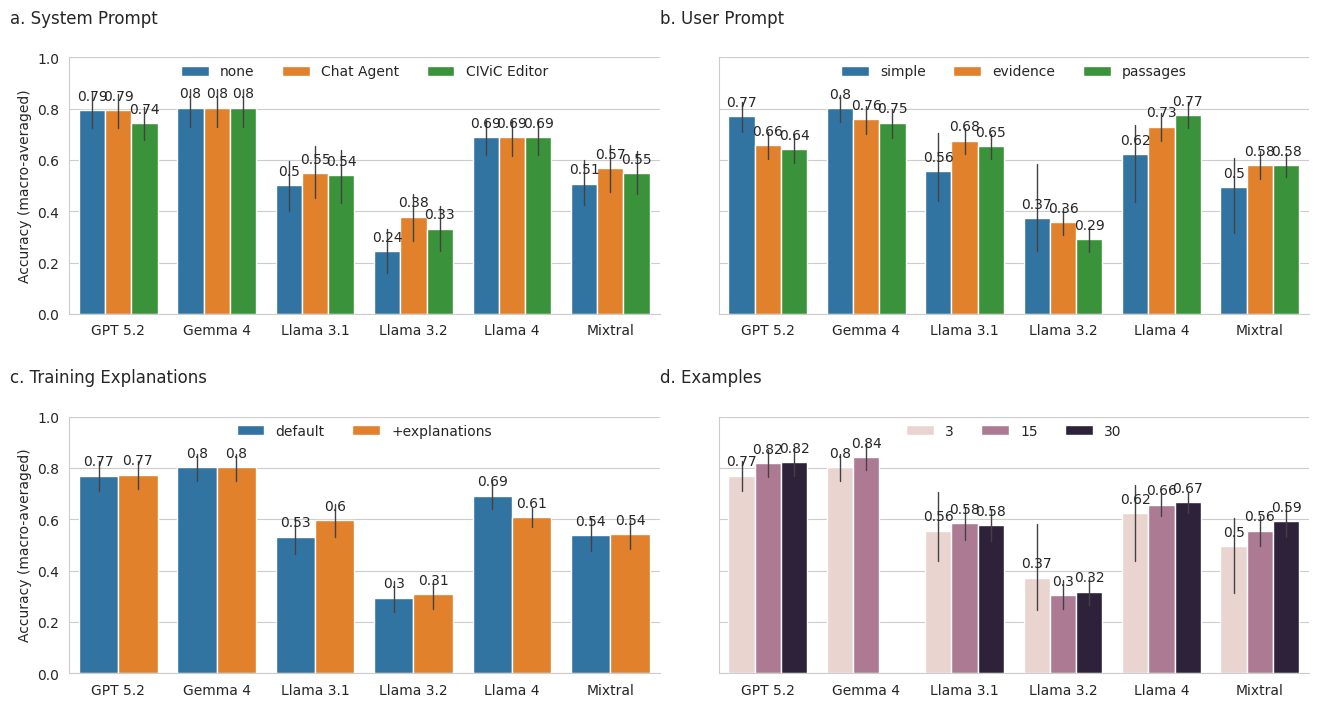

In [13]:
import matplotlib.gridspec as gridspec
from matplotlib import pyplot as plt
import seaborn as sns

from utils.fig import generate_hue_map, add_bar_labels
from utils import ci_95

def remove_top_right(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Set the base font size globally
plt.rcParams.update({'font.size': 10})
bar_kws = dict(err_kws={'linewidth': 1}, estimator='mean', errorbar=ci_95)

sns.set_style('whitegrid')

palette = generate_hue_map(sorted(system_df.model.unique()), 'tab10')

fig = plt.figure(figsize=(16, 8), tight_layout=True)
gs = fig.add_gridspec(nrows=2, ncols=2, hspace=0.4, wspace=0.1)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1], sharex=ax1)
ax3 = fig.add_subplot(gs[1, 0], sharex=ax1)
ax4 = fig.add_subplot(gs[1, 1], sharex=ax1)

system_df['system_prompt'] = system_df['system_prompt'].apply(lambda x: {'civic_editor.md': 'CIViC Editor', 'chatgpt.md': 'Chat Agent'}.get(x, x))
system_df['system_prompt_order'] = system_df.system_prompt.apply(lambda sp: ['none', 'Chat Agent', 'CIViC Editor'].index(sp))
system_df = system_df[system_df['system_prompt'] != 'none think[high]'].sort_values(['system_prompt_order'])
sns.barplot(system_df.sort_values('model'), x='model', y='macro_avg.accuracy', hue='system_prompt', ax=ax1, **bar_kws)
add_bar_labels(ax1, fmt=lambda x: round(x, 2), padding=5)

user_prompt_df['order'] = user_prompt_df['user prompt'].apply(lambda sp: ['simple', 'evidence', 'passages'].index(sp))
user_prompt_df = user_prompt_df.sort_values(['order'])
sns.barplot(user_prompt_df.sort_values('model'), x='model', y='macro_avg.accuracy', hue='user prompt', ax=ax2, **bar_kws)
add_bar_labels(ax2, fmt = lambda v: round(v, 2), padding=5)


for ax in [ax2, ax4]:
    ax.set_ylabel('')
    plt.setp(ax.get_yticklabels(), visible=False)

for ax in [ax1, ax3]:
    ax.set_ylabel('Accuracy (macro-averaged)')


sns.barplot(data=expl_df, y='macro_avg.accuracy', x='model', hue='dataset', ax=ax3, **bar_kws)
add_bar_labels(ax3, fmt=lambda x: round(x, 2), padding=5)

shot_df['Examples'] = shot_df['filepath.examples']
sns.barplot(data=shot_df.sort_values('model'), y='macro_avg.accuracy', hue='Examples', x='model', ax=ax4, **bar_kws)
ax4.set_xlabel('Examples')
add_bar_labels(ax4, fmt=lambda x: round(x, 2), padding=5)

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_ylim(0, 1)
    ax.legend(title="")
    sns.move_legend(ax, frameon=False, loc='upper center', ncols=3, bbox_to_anchor=(0.5, 1.02))
    ax.set_xlabel('')
    remove_top_right(ax)

for ax, title, part in zip([ax1, ax2, ax3, ax4], ['System Prompt', 'User Prompt', "Training Explanations", "Examples"], 'abcd'):

    ax.set_title(part + '. ' + title, loc='left', y=1.1, x=-0.1)
